# Question 3

3.1 Generate a dataframe Of research articles including all articles and their respective content.

In [7]:
import pandas as pd
import glob
import os

# finding all research text files in the current folder.
# The * matches any characters between "research_" and ".txt".
files = sorted(glob.glob("research_corpus/research_*.txt"))

# read each article and store its filename and full content.
articles = []

for file in files:
    with open(file, "r", encoding="utf-8") as f:
        text = f.read()

    articles.append({"File": os.path.basename(file), "Article": text })

# Create a DataFrame containing all articles and their content.
df_articles = pd.DataFrame(articles)

# Display the filenames and confirm that all articles were loaded.
print("Number of articles:", len(df_articles))
display(df_articles[["File"]])

# Check that the full article content is stored.
display(df_articles[["File", "Article"]].head())

df_articles["Article"].str.len()

Number of articles: 5


,File
0,research_1.txt
1,research_2.txt
2,research_3.txt
3,research_4.txt
4,research_5.txt


,File,Article
0,research_1.txt,The purposes of this article are to position m...
1,research_2.txt,"Now I see it, now I don’t:\nresearcher’s posit..."
2,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...
3,research_4.txt,Abstract\nCronbach’s alpha is a statistic comm...
4,research_5.txt,Denzin’s Paradigm Shift: Revisiting Triangulat...


0    38160
1    16104
2    26154
3    38950
4    26831
Name: Article, dtype: int64

3.2 preprocess each research article content using state—of-the art denoising techniques.

In [8]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download the language resources needed for preprocessing
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

# Prepare the tools for cleaning the text
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

# Clean and preprocess an article
def denoise_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove URLs and email addresses
    text = re.sub(r'http\S+|www\.\S+|\S+@\S+', ' ', text)

    # Remove apostrophes without splitting contractions into fragments
    text = re.sub(r"(?<=\w)['’](?=\w)", '', text)

    # Remove punctuation, numbers and unwanted characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    # Tokenise the text into individual words
    words = text.split()

    # Remove stop words and lemmatise the remaining words
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words]
    return ' '.join(words)

# Apply denoising to all five research articles
df_articles["Denoised_Article"] = df_articles["Article"].apply(denoise_text)

# Display the results
display(df_articles[["File", "Denoised_Article"]].head(5))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\xikon\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\xikon\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\xikon\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


,File,Denoised_Article
0,research_1.txt,purpose article position mixed method research...
1,research_2.txt,see dont researcher position reflexivity quali...
2,research_3.txt,developmental research study instructional des...
3,research_4.txt,abstract cronbachs alpha statistic commonly qu...
4,research_5.txt,denzins paradigm shift revisiting triangulatio...


3.3 Summarize the information content in the first article using a summarization technique choice including
Visualization.

In [9]:
import nltk
from sumy.parsers.plaintext import PlaintextParser
from sumy.nlp.tokenizers import Tokenizer
from sumy.summarizers.text_rank import TextRankSummarizer

# Get the original text of the first research article
article_text = df_articles.loc[0, "Article"]

# Prepare the article for summarisation
parser = PlaintextParser.from_string(article_text, Tokenizer("english"))

# apply textRank summarisation
summarizer = TextRankSummarizer()
summary_sentences = summarizer(parser.document, 5)

# Display the summary
summary = " ".join(str(sentence) for sentence in summary_sentences)

print("Text rank summary — Research Article 1")
print(summary)
print("\nNumber of summary sentences:", len(summary_sentences))

Text rank summary — Research Article 1
The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research. In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative research, we explain the tenets of pragmatism, we explain the fundamental principle of mixed research and how to apply it, we provide specific sets of designs for the two major types of mixed methods research (mixed-model designs and mixed-method designs), and, finally, we explain mixed methods research as following (recursively) an eight-step process. Basic agreement has been reached on each of the following issues: (a) the relativity of the “light of rea

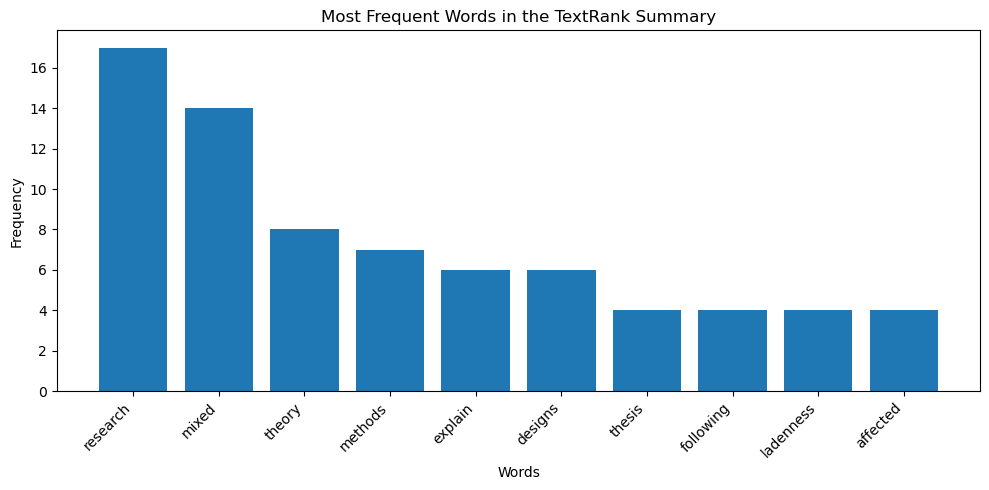

In [10]:

import re
import matplotlib.pyplot as plt
from collections import Counter
from nltk.corpus import stopwords

# Remove common English words so the chart focuses on meaningful terms.
stop_words = set(stopwords.words("english"))

words = re.findall(r"\b[a-zA-Z]+\b", summary.lower())

summary_words = [a
    word for word in words
    if word not in stop_words and len(word) > 2
]

word_counts = Counter(summary_words).most_common(10)

# Display the most frequent words in a bar chart.
terms, counts = zip(*word_counts)

plt.figure(figsize=(10, 5))
plt.bar(terms, counts)
plt.title("Most Frequent Words in the TextRank Summary")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

3.4 Summarise as an aggrate the remaining articles in the corpus using another summarization technique of your
choice induding appropriate visualization methods

In [11]:
# Select the remaining four articles and combine their original text
remaining_articles = df_articles.loc[1:, "Article"]
combined_text = " ".join(remaining_articles)
print("Number of remaining articles:", len(remaining_articles))
print("Total words:", len(combined_text.split()))

Number of remaining articles: 4
Total words: 16193


,Term,TF-IDF Score
7,research,0.474424
0,alpha,0.211644
8,study,0.204907
9,triangulation,0.191766
2,data,0.183612
4,development,0.177396
3,design,0.151416
6,knowledge,0.118258
1,cronbach,0.095495
5,instrument,0.087978


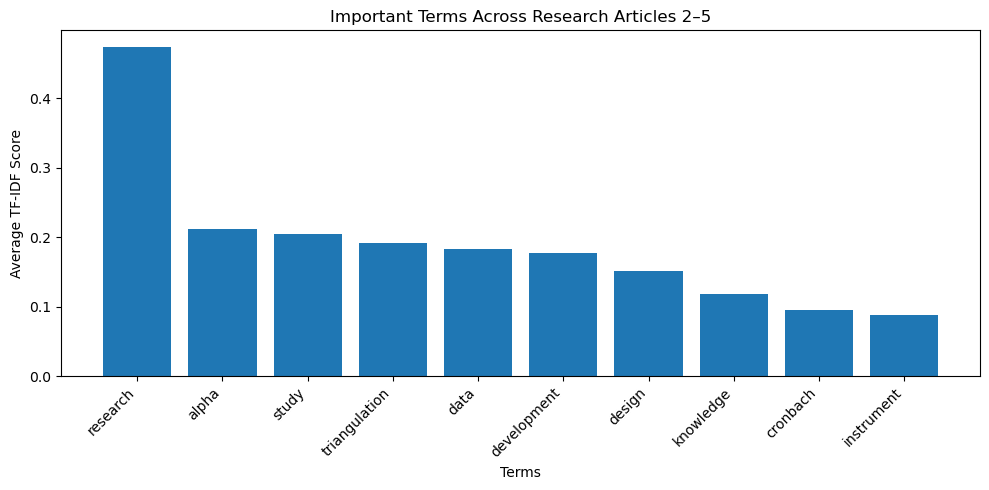

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd
import matplotlib.pyplot as plt

# treat each remaining article as a separate document.
vectorizer = TfidfVectorizer(stop_words="english",max_features=10)

tfidf_matrix = vectorizer.fit_transform(remaining_articles)

# Find the average tf-idf score of each term across the articles.
terms = vectorizer.get_feature_names_out()
scores = tfidf_matrix.mean(axis=0).A1

term_scores = pd.DataFrame({"Term": terms,"TF-IDF Score": scores}).sort_values("TF-IDF Score", ascending=False)

display(term_scores)

# Visualise the terms with the highest average TF-IDF scores.
plt.figure(figsize=(10, 5))
plt.bar(term_scores["Term"], term_scores["TF-IDF Score"])
plt.title("Important Terms Across Research Articles 2–5")
plt.xlabel("Terms")
plt.ylabel("Average TF-IDF Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [13]:
from sumy.parsers.plaintext import PlaintextParser
from sumy.nlp.tokenizers import Tokenizer
from sumy.summarizers.lsa import LsaSummarizer

# Prepare the combined text of Articles 2–5.
parser = PlaintextParser.from_string(combined_text, Tokenizer("english"))

# using LSA to select important sentences.
summarizer_lsa = LsaSummarizer()
summary_sentences_lsa = summarizer_lsa(parser.document, 10)

# Combine and display the selected sentences.
collective_summary = " ".join(str(sentence) for sentence in summary_sentences_lsa)

print("LSA Summary Research articles 2–5")
print(collective_summary)
print("\nNumber of summary sentences:", len(summary_sentences_lsa))

LSA Summary Research articles 2–5
This article discusses issues relative to reflexivity under varying types of researcher’s personal experience with the world being studied and illustrates them using my own work. Qualitative research primarily contributes to the development of “mirrors for man” so that we can see ourselves better (Kluckhohn, as noted in Diesing, 1991). This conceptual framework not only has been commonly subscribed to, but was subsequently extended into the research, development, and diffusion model (Brickell, Clark & Guba, as cited in Havelock, 1971). We have learned from the research literature that transfer of training is impacted by motivation, organizational climate, and previous educational experiences. Therefore, one may expand a front-end analysis to address such issues, or even construct design models that reflect this information, but the foundational research would not be considered developmental. Guidance is offered to authors reporting, and readers evaluat

In [14]:
# Display the LSA summary as separate sentences for inspection.
for i, sentence in enumerate(summary_sentences_lsa, start=1):
    print(f"{i}. {sentence}\n")

1. This article discusses issues relative to reflexivity under varying types of researcher’s personal experience with the world being studied and illustrates them using my own work.

2. Qualitative research primarily contributes to the development of “mirrors for man” so that we can see ourselves better (Kluckhohn, as noted in Diesing, 1991).

3. This conceptual framework not only has been commonly subscribed to, but was subsequently extended into the research, development, and diffusion model (Brickell, Clark & Guba, as cited in Havelock, 1971).

4. We have learned from the research literature that transfer of training is impacted by motivation, organizational climate, and previous educational experiences.

5. Therefore, one may expand a front-end analysis to address such issues, or even construct design models that reflect this information, but the foundational research would not be considered developmental.

6. Guidance is offered to authors reporting, and readers evaluating, studie

In [15]:
# Generate a longer LSA summary so we have more sentences to choose from.
summary_sentences_lsa = summarizer_lsa(parser.document, 15)

# Remove very short sentence fragments and duplicate sentences.
clean_summary_sentences = []
seen_sentences = set()

for sentence in summary_sentences_lsa:
    sentence_text = str(sentence).strip()
    sentence_key = sentence_text.lower()

    if len(sentence_text.split()) >= 8 and sentence_key not in seen_sentences:
        clean_summary_sentences.append(sentence_text)
        seen_sentences.add(sentence_key)

collective_summary = " ".join(clean_summary_sentences)

print("Improved LSA Summary Research Articles 2–5\n")
print(collective_summary)
print("\nNumber of selected sentences:", len(clean_summary_sentences))

Improved LSA Summary Research Articles 2–5

This article discusses issues relative to reflexivity under varying types of researcher’s personal experience with the world being studied and illustrates them using my own work. Qualitative research primarily contributes to the development of “mirrors for man” so that we can see ourselves better (Kluckhohn, as noted in Diesing, 1991). This conceptual framework not only has been commonly subscribed to, but was subsequently extended into the research, development, and diffusion model (Brickell, Clark & Guba, as cited in Havelock, 1971). Such activities “could change the development of products into research with empirical results and theory generalizable to new problems” (p. 148). We have learned from the research literature that transfer of training is impacted by motivation, organizational climate, and previous educational experiences. Therefore, one may expand a front-end analysis to address such issues, or even construct design models that

In [16]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


Collective Summary — Research Articles 2–5

This article discusses issues relative to reflexivity under varying types of researcher’s personal experience with the world being studied and illustrates them using my own work. Qualitative research primarily contributes to the development of “mirrors for man” so that we can see ourselves better (Kluckhohn, as noted in Diesing, 1991). This conceptual framework not only has been commonly subscribed to, but was subsequently extended into the research, development, and diffusion model (Brickell, Clark & Guba, as cited in Havelock, 1971). Such activities “could change the development of products into research with empirical results and theory generalizable to new problems” (p. 148). We have learned from the research literature that transfer of training is impacted by motivation, organizational climate, and previous educational experiences. Therefore, one may expand a front-end analysis to address such issues, or even construct design models that

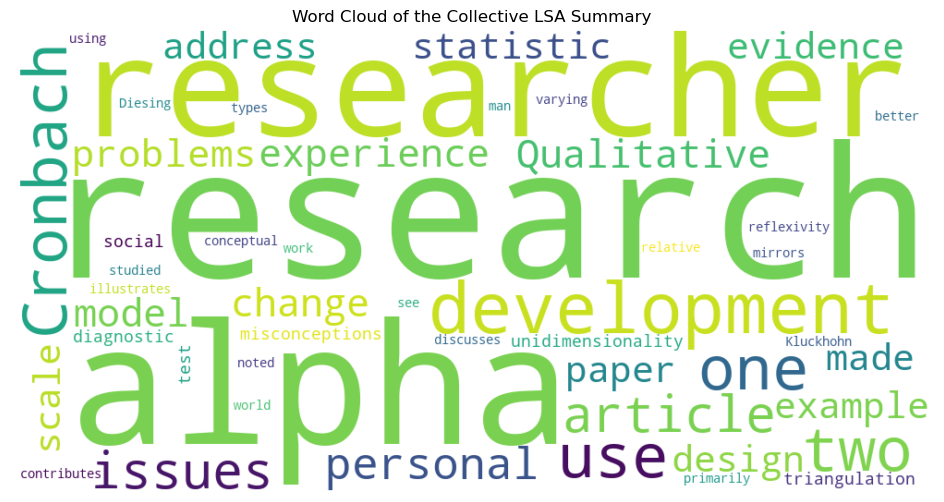

In [17]:
import re
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Remove the incomplete alpha statistic fragment from the summary.
clean_collective_summary = re.sub( r"fairly high; not satisfactory.*?somewhat arbitrary\.", "", collective_summary,  flags=re.IGNORECASE).strip()

# Display the cleaned collective summary.
print("Collective Summary of Research Articles 2–5\n")
print(clean_collective_summary)

# Create a word cloud from the collective summary.
wordcloud = WordCloud( width=1000, height=500, background_color="white", stopwords=set(stop_words), max_words=50).generate(clean_collective_summary)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of the Collective LSA Summary")
plt.show()

In [1]:
!zip -r folder_archive.zip Xikongomelo Max Mabunda - ITNPA4-34 - Project 1 - Eduvos Online - 2026

'zip' is not recognized as an internal or external command,
operable program or batch file.
